### **Student Information**
GitHub ID: Rabbit025879

Kaggle name: rabbit025879

Kaggle private scoreboard snapshot:

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**.

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements:
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---

## 1. Model Development (10 pts Required)

### 1.1 Preprocessing Steps

**Data:** `final_posts.json` contains 4,800 posts (3,360 train / 1,440 test) with 6 emotion labels. The classes are imbalanced:

| joy | anger | sadness | disgust | surprise | fear |
| --- | --- | --- | --- | --- | --- |
| 875 | 674 | 628 | 454 | 441 | 288 |

**Preprocessing (`clean_text`):**
* Curly quotes are converted to straight quotes.
* URLs are replaced with `URL` and user mentions with `USER`.
* Characters repeated 4 or more times are shortened to 3 (e.g. sooooo → sooo).
* Extra whitespace is removed.

Punctuation, emoji, capitalisation and stopwords are **kept on purpose**. The attention mechanism of a transformer can already find how words relate to each other, so removing too much might delete important words.

**Data checks:**
* No missing values and no duplicated `post_id`.
* 99% of posts have 84 words or fewer, so `MAX_LEN = 128` almost never cuts off text.
* The training set has 50 groups of posts with identical text, and 16 of these groups have conflicting labels. This means a model cannot reach 100% accuracy: the same sentence can belong to two classes, but we can only predict one.

### 1.2 Feature Engineering Steps

* **Model A (TF-IDF):** word TF-IDF 1–2 grams plus char_wb TF-IDF 1–4 grams (`min_df=2`, `sublinear_tf=True`), combined with `make_union`, 53,180 features in total.
* **Model B / C (transformers):** no hand-crafted features. The tokenizer and encoder of each pre-trained model produce the representation of every post.

TF-IDF only looks at which words appear, not at their meaning, so it stopped at 0.517. Transformers are more complex and explain the data better, reaching above 0.62. Models that were pre-trained on emotion data have already learned what different emotions mean, so they work better than general pre-trained models.

### 1.3 Explanation of Your Model

The work had three stages:

| Stage | Method | Macro F1 |
| --- | --- | --- |
| Model A | TF-IDF + Linear SVM (C=0.2, class_weight=balanced) | 5-fold CV 0.517 |
| Model B | Fine-tune 5 transformers on one 90/10 split and average their probabilities | validation ≈ 0.62 |
| Model C | 5-fold training of emotion-pretrained models only, averaging their probabilities | OOF 0.643–0.649 |

**Model B** fine-tuned `roberta-base`, `j-hartmann/emotion-english-distilroberta-base`, `SamLowe/roberta-base-go_emotions`, `roberta-large` and `microsoft/deberta-v3-base`.

**Model C** switched to 5-fold cross-validation: each part of the data takes turns being the training and validation data, so every training post gets an out-of-fold (OOF) prediction from a model that never saw it. This improves training and generalisation. Models used:

| Model | lr, epochs | OOF macro F1 |
| --- | --- | --- |
| `j-hartmann/emotion-english-roberta-large` | 1e-5, 3 | 0.6298 |
| `SamLowe/roberta-base-go_emotions` | 2e-5, 3 | 0.6276 |
| `j-hartmann/emotion-english-distilroberta-base` | 2e-5, 3 | 0.6180 |
| `cardiffnlp/twitter-roberta-base-emotion-latest` | 2e-5, 3 | 0.6073 |
| `bhadresh-savani/distilbert-base-uncased-emotion` | 3e-5, 4 | 0.5737 |

**Detecting overfitting:** when the training loss keeps going down but the validation performance gets worse, the model is overfitting. For example, with roberta-base at 6 epochs the validation F1 stopped improving after epoch 3, and with DeBERTa at 8 epochs the training loss dropped to 0.15 while the validation F1 fell after epochs 3–4.

**Not used:**
* DeBERTa: its own performance was weaker (5-fold OOF 0.581), so it was not used.
* Class weights, model weights and stacking: tuned on one half of the data and checked on the other half, none of them beat a plain average.

**Kaggle results:**

| Submission | Models | val / OOF | Public | Private |
| --- | --- | --- | --- | --- |
| `submission_transformer.csv` | roberta-base | 0.6186 | 0.6005 | 0.6225 |
| `submission_transformer-emotional-model.csv` | j-hartmann distilroberta | 0.628 | 0.5861 | 0.6134 |
| `submission_ensemble.csv` | Model B average | ≈ 0.62 | 0.6180 | 0.6403 |
| `submission_kfold_2models.csv` | base + go_emotions | 0.6429 | 0.6334 | 0.6389 |
| `submission_kfold_large_3_model.csv` | base + go_emotions + large | 0.6477 | 0.6206 | **0.6534** |
| `submission_kfold_4_model.csv` | the three above + bhadresh | 0.6443 | 0.6156 | 0.6474 |
| `submission_kfold_4_model_unique.csv` | the three above + cardiffnlp | 0.6494 | **0.6404** | 0.6398 |

![kaggle_submissions.png](./pics/submissions.png)

The selected submissions were `4_model_unique` and `2models` (private 0.6398, rank 45).

**Conclusions:**
* Ensembling works well and improves generalisation: every ensemble scored higher on private than the single models.
* The large model explains the data better: the 3-model ensemble with the large model had the best private score.
* The public score is not very reliable: everyone's scores are close (about 0.60–0.67), so once the private data is used, the ranking changes a lot.
* If I did it again, I would choose the 3-model k-fold ensemble with the large model, which had the highest private score.

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

I used Claude to help with this competition. The process was:

1. I first asked the AI to help build a TF-IDF + SVM baseline, which reached CV 0.517.
2. Then I moved to more complex models. The AI recommended RoBERTa models pre-trained on emotion data; the score went up, so I adopted them.
3. I tuned parameters such as the number of epochs and the learning rate, and found the effect was small.
4. I asked if there are different model to try, so I tested DeBERTa but found it did not perform well.
5. I noticed that my validation scores were high but my Kaggle scores were lower, so I asked for advise and the reason. It suggested me to add an ensemble that averages the models' results to improve generalisation.
6. After confirming DeBERTa performed poorly, I removed it from the ensemble.
7. I noticed that scores varied a lot between epochs and between runs, so I added 5-fold cross-validation to make the evaluation more stable.
8. I compared the OOF scores of different model combinations, then uploaded them to Kaggle to compare public scores.
9. Finally, I asked the AI whether my backup submission should be the 2-model ensemble or the 3-model ensemble with the large model. The AI recommended the 2-model one, but afterwards the 3-model ensemble had the highest private score.

The AI also explained how to use Google Colab, provided the code implementation, and helped organize the wording, format, and English translation of this report.

---


**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

The competition files (`final_posts.json`, `data_identification.csv`, `emotion.csv`, `sampleSubmission.csv`) are downloaded from the Kaggle **Data** page and placed in `DATA_DIR`. They are not part of the repository.

In [ ]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd

# Configure data directory path and random seed for reproducibility
DATA_DIR = Path("/content")
print("data folder:", DATA_DIR)
SEED = 42

# Load raw posts, train/test split assignments, training labels, and submission template
posts = pd.DataFrame(json.loads((DATA_DIR / "final_posts.json").read_text(encoding="utf-8")))
split = pd.read_csv(DATA_DIR / "data_identification.csv")
labels = pd.read_csv(DATA_DIR / "emotion.csv")
sample_sub = pd.read_csv(DATA_DIR / "sampleSubmission.csv")

# Merge posts with split metadata, then separate into labeled train_df and unlabeled test_df
df = posts.merge(split, on="post_id", how="inner")
train_df = df[df["set"] == "train"].merge(labels, on="post_id", how="inner").reset_index(drop=True)
test_df = df[df["set"] == "test"].reset_index(drop=True)

# Verify dataset dimensions and ensure all expected submission post_ids exist in test_df
print("posts:", posts.shape, "| train:", train_df.shape, "| test:", test_df.shape)
assert set(sample_sub["post_id"]) == set(test_df["post_id"])

data folder: /content
posts: (4800, 2) | train: (3360, 4) | test: (1440, 3)


In [ ]:
# Verify text completeness and post_id uniqueness across the full dataset
print("missing text:", df["text"].isna().sum())
print("duplicated post_id:", df["post_id"].duplicated().sum())

# Check class distribution in the training set to identify label imbalance
print("\nlabel distribution (train):")
print(train_df["label"].value_counts())

# Compute summary statistics (mean, std, min, quartiles, max) for post word counts
print("\nwords per post (train):")
print(train_df["text"].str.split().str.len().describe().round(1))

missing text: 0
duplicated post_id: 0

label distribution (train):
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64

words per post (train):
count    3360.0
mean       16.5
std        25.0
min         1.0
25%         8.0
50%        13.0
75%        19.0
max       508.0
Name: text, dtype: float64


In [ ]:
def clean_text(text: str) -> str:
    """Light normalization that preserves punctuation and emoticons as emotional cues."""
    text = str(text)
    # Standardize curly quotes and apostrophes to straight ASCII equivalents
    text = text.replace("’", "'").replace("‘", "'")
    text = text.replace("“", '"').replace("”", '"')
    
    # Replace URLs and user mentions (Reddit u/ and Twitter @) with generic tokens
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"/?u/\w+|@\w+", " USER ", text)
    
    # Cap repeated characters at 3 (e.g., "sooooo" -> "sooo") to preserve emphasis without exploding vocabulary
    text = re.sub(r"(.)\1{3,}", r"\1\1\1", text)
    
    # Collapse consecutive whitespace/newlines into a single space and trim ends
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Apply text cleaning to both train and test sets and preview results
train_df["clean"] = train_df["text"].map(clean_text)
test_df["clean"] = test_df["text"].map(clean_text)
train_df[["text", "clean", "label"]].head()

,text,clean,label
0,Thought it looked weird as well.,Thought it looked weird as well.,disgust
1,Bear died in a pit,Bear died in a pit,disgust
2,I have endured worse.,I have endured worse.,sadness
3,The pottery around Brasov is in danger,The pottery around Brasov is in danger,fear
4,"Meanwhile, our soldiers were approaching the a...","Meanwhile, our soldiers were approaching the a...",fear


## 2. Feature Engineering Steps

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_union

def build_features():
    """Combine word and character TF-IDF matrices to capture both semantics and subword patterns."""
    # Word 1-2 grams capture emotion words and short negation/emphasis phrases (e.g., "not fair")
    word = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, lowercase=True)
    # Character 1-4 grams (within word boundaries) handle typos, slang, and elongated words
    # sublinear_tf (1 + log(tf)) dampens the impact of heavily repeated terms
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4), min_df=2,
                           sublinear_tf=True, lowercase=True)
    # Concatenate word and character feature matrices horizontally
    return make_union(word, char)

# Fit feature union on training text, transform both splits, and print matrix shapes
features = build_features()
X_train = features.fit_transform(train_df["clean"])
X_test = features.transform(test_df["clean"])
print("train matrix:", X_train.shape, "| test matrix:", X_test.shape)

train matrix: (3360, 53180) | test matrix: (1440, 53180)


## 3. Model Implementation Steps

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB

# Configure 5-fold stratified CV to preserve class ratios across folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Define candidate pipelines (bundling vectorizers inside prevents data leakage during CV)
# class_weight="balanced" compensates for class imbalance in linear models
candidates = {
    "Complement NB (word TF-IDF)": make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), ComplementNB(alpha=0.3)),
    "Logistic Regression (word+char)": make_pipeline(
        build_features(), LogisticRegression(C=10, max_iter=3000, class_weight="balanced")),
    "Linear SVM (word+char)": make_pipeline(
        build_features(), LinearSVC(C=0.2, class_weight="balanced")),
}

# Evaluate all models on macro F1 across all folds and report mean ± standard deviation
cv_scores = {}
for name, pipe in candidates.items():
    scores = cross_val_score(pipe, train_df["clean"], train_df["label"], cv=cv, scoring="f1_macro", n_jobs=-1)
    cv_scores[name] = scores
    print(f"{name:35s} macro F1 = {scores.mean():.4f} ± {scores.std():.4f}")

Complement NB (word TF-IDF)         macro F1 = 0.4706 ± 0.0191
Logistic Regression (word+char)     macro F1 = 0.5005 ± 0.0170
Linear SVM (word+char)              macro F1 = 0.5172 ± 0.0170


              precision    recall  f1-score   support

       anger      0.491     0.540     0.514       674
     disgust      0.409     0.333     0.367       454
        fear      0.591     0.483     0.532       288
         joy      0.620     0.663     0.641       875
     sadness      0.556     0.570     0.563       628
    surprise      0.497     0.490     0.493       441

    accuracy                          0.538      3360
   macro avg      0.527     0.513     0.518      3360
weighted avg      0.535     0.538     0.535      3360



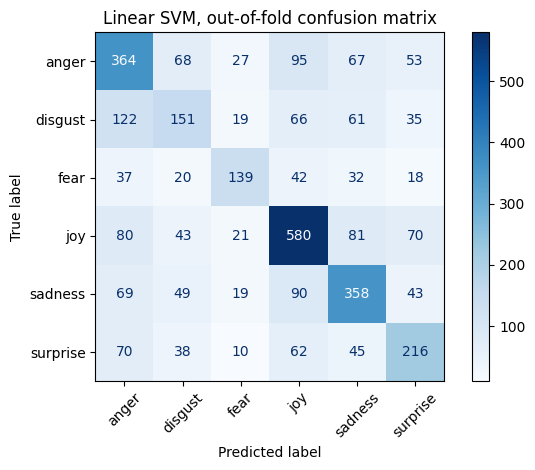

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict

# Generate out-of-fold (OOF) predictions using the best performing Linear SVM pipeline
best_pipe = make_pipeline(build_features(), LinearSVC(C=0.2, class_weight="balanced"))
oof = cross_val_predict(best_pipe, train_df["clean"], train_df["label"], cv=cv, n_jobs=-1)

# Print per-class precision, recall, and F1 scores for error analysis
print(classification_report(train_df["label"], oof, digits=3))

# Plot confusion matrix to visualize which emotion classes are most frequently confused
ConfusionMatrixDisplay.from_predictions(train_df["label"], oof, xticks_rotation=45, cmap="Blues")
plt.title("Linear SVM, out-of-fold confusion matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Train final Linear SVM on the full training dataset and generate test predictions
svm = LinearSVC(C=0.2, class_weight="balanced")
svm.fit(X_train, train_df["label"])
submission = pd.DataFrame({"post_id": test_df["post_id"], "label": svm.predict(X_test)})

# Align prediction row order with sampleSubmission.csv and verify no missing labels or row mismatches
submission = sample_sub[["post_id"]].merge(submission, on="post_id", how="left")
assert submission["label"].notna().all() and len(submission) == len(sample_sub)

# Rename ID column to match Kaggle's required format, export to CSV, and check predicted class counts
submission.rename(columns={"post_id": "id"}).to_csv("submission_tfidf_svm.csv", index=False)
print(submission["label"].value_counts())

label
joy         409
anger       316
sadness     272
surprise    183
disgust     145
fear        115
Name: count, dtype: int64


### Model B (GPU): fine-tuned transformers and their ensemble

TF-IDF plateaus around 0.52 macro F1, because it only sees which words occur. Pre-trained transformers read each sentence in context. Several of them are fine-tuned here on the same 90/10 split; for each one the class probabilities of its best epoch are kept, and the ensemble averages those probabilities. Run on Colab with a GPU.

- `roberta-base`: general pre-trained English model.
- `j-hartmann/emotion-english-distilroberta-base`: already trained on emotion datasets (7 classes incl. neutral; its head is replaced by a new 6-class head).
- `SamLowe/roberta-base-go_emotions`: trained on GoEmotions, 58k Reddit comments with 27 emotion labels.
- `roberta-large`: about 3x larger than roberta-base; smaller learning rate.
- `microsoft/deberta-v3-base`: a newer architecture (disentangled attention) that is often stronger than RoBERTa on classification; trained in full precision.

In [ ]:
import gc, time
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

RUN_TRANSFORMER = True  # Toggle GPU-based transformer training
SAVE_TO_DRIVE = True    # Persist outputs to Google Drive when running on Colab

# Configure output directory (Colab Drive, Kaggle working dir with cached inputs, or local)
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and SAVE_TO_DRIVE:
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/dm2026_kaggle_runs")
elif Path("/kaggle/working").exists():
    # Copy any previously saved .npz probability files from Kaggle input datasets to resume progress
    import shutil
    OUT_DIR = Path("/kaggle/working/runs")
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    for f in Path("/kaggle/input").rglob("*.npz"):
        if not (OUT_DIR / f.name).exists():
            shutil.copy(f, OUT_DIR / f.name)
else:
    OUT_DIR = Path("runs")

OUT_DIR.mkdir(parents=True, exist_ok=True)
print("results folder:", OUT_DIR, "| already finished:", sorted(p.stem for p in OUT_DIR.glob("*.npz")))

# Set max token length and select best available compute device (CUDA > MPS > CPU)
MAX_LEN = 128
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

# Encode string labels to integer IDs
label_names = sorted(train_df["label"].unique())
label2id = {n: i for i, n in enumerate(label_names)}
y_all = train_df["label"].map(label2id).to_numpy()

# Create a fixed 90/10 stratified train/validation split for consistent evaluation across models
tr_idx, va_idx = train_test_split(np.arange(len(train_df)), test_size=0.1, stratify=y_all, random_state=SEED)
y_val = y_all[va_idx]
print("train:", len(tr_idx), "| val:", len(va_idx), "| test:", len(test_df))

Mounted at /content/drive
results folder: /content/drive/MyDrive/dm2026_kaggle_runs | already finished: ['SamLowe__roberta-base-go_emotions', 'j-hartmann__emotion-english-distilroberta-base', 'kfold_SamLowe__roberta-base-go_emotions_fold0', 'kfold_SamLowe__roberta-base-go_emotions_fold1', 'kfold_SamLowe__roberta-base-go_emotions_fold2', 'kfold_SamLowe__roberta-base-go_emotions_fold3', 'kfold_SamLowe__roberta-base-go_emotions_fold4', 'kfold_j-hartmann__emotion-english-distilroberta-base_fold0', 'kfold_j-hartmann__emotion-english-distilroberta-base_fold1', 'kfold_j-hartmann__emotion-english-distilroberta-base_fold2', 'kfold_j-hartmann__emotion-english-distilroberta-base_fold3', 'kfold_j-hartmann__emotion-english-distilroberta-base_fold4', 'kfold_microsoft__deberta-v3-base_fold0', 'kfold_microsoft__deberta-v3-base_fold0_5ep', 'kfold_microsoft__deberta-v3-base_fold1', 'kfold_microsoft__deberta-v3-base_fold1_5ep', 'kfold_microsoft__deberta-v3-base_fold2_5ep', 'kfold_microsoft__deberta-v3-ba

In [ ]:
# Define candidate Hugging Face transformer checkpoints and training hyperparameters
# Tuple format: (model_name, learning_rate, epochs, batch_size, [optional: use_fp16])
MODELS = [
    ("SamLowe/roberta-base-go_emotions",               2e-5, 4,      16),
    ("j-hartmann/emotion-english-distilroberta-base",  2e-5, 4,      16),
    ("roberta-base",                                   2e-5, 4,      16),
    ("roberta-large",                                  1e-5, 4,      16),        # Lower LR for larger model stability
    ("microsoft/deberta-v3-base",                      2e-5, 4,      16,     False), # Disable fp16 to prevent gradient overflow
]

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

def encode(tokenizer, texts, y=None):
    """Tokenize texts into padded PyTorch tensors, optionally attaching label IDs."""
    enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt")
    t = [enc["input_ids"], enc["attention_mask"]]
    if y is not None:
        t.append(torch.tensor(y))
    return TensorDataset(*t)

@torch.no_grad()
def predict_proba(model, ds, use_amp=True):
    """Run inference over a dataset and return softmax class probabilities."""
    model.eval()
    out = []
    for b in DataLoader(ds, batch_size=64):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp and device == "cuda"):
            logits = model(input_ids=b[0].to(device), attention_mask=b[1].to(device)).logits
        out.append(torch.softmax(logits.float(), dim=-1).cpu())
    return torch.cat(out).numpy()

def run_model(name, lr, epochs, batch, fp16=True, load_model=None, load_tokenizer=None, select_best=True):
    """Fine-tune a transformer model and return (val_macro_F1, val_probs, test_probs)."""
    torch.manual_seed(SEED)
    tok = load_tokenizer(name) if load_tokenizer else AutoTokenizer.from_pretrained(name)
    
    # Load pretrained model and adapt the classification head to our target labels
    if load_model:
        model = load_model(name)
    else:
        model = AutoModelForSequenceClassification.from_pretrained(
            name, num_labels=len(label_names),
            id2label={i: n for n, i in label2id.items()}, label2id=label2id,
            problem_type="single_label_classification",   # Override multi-label defaults (e.g., go_emotions)
            ignore_mismatched_sizes=True)                   # Reinitialize classifier head for new class count
    
    # Cast weights to float32 to prevent NaN losses in models stored in fp16 (e.g., DeBERTa-v3)
    model = model.float().to(device)
    
    # Prepare DataLoaders, AdamW optimizer, linear warmup scheduler, and AMP gradient scaler
    tr_ds = encode(tok, train_df["clean"].iloc[tr_idx], y_all[tr_idx])
    va_ds = encode(tok, train_df["clean"].iloc[va_idx], y_val)
    te_ds = encode(tok, test_df["clean"])
    loader = DataLoader(tr_ds, batch_size=batch, shuffle=True)
    optim = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total = len(loader) * epochs
    sched = get_linear_schedule_with_warmup(optim, int(0.1 * total), total)
    use_amp = fp16 and device == "cuda"
    scaler = torch.amp.GradScaler(enabled=use_amp)
    
    best = (-1.0, None, None)
    for ep in range(epochs):
        model.train()
        losses = []
        for ids, mask, y in loader:
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = model(input_ids=ids.to(device), attention_mask=mask.to(device), labels=y.to(device)).loss
            
            # Skip batch if loss becomes NaN/Inf to protect model weights
            if not torch.isfinite(loss):
                optim.zero_grad(); continue
                
            losses.append(loss.item())
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0) # Prevent exploding gradients
            scaler.step(optim); scaler.update(); sched.step(); optim.zero_grad()
            
        # Evaluate on validation set after each epoch
        p_val = predict_proba(model, va_ds, use_amp)
        f1 = f1_score(y_val, p_val.argmax(1), average="macro")
        print(f"  epoch {ep + 1}: train loss = {np.mean(losses) if losses else float('nan'):.4f}, validation macro F1 = {f1:.4f}")
        
        # Save best checkpoint probabilities (or final epoch if select_best=False for unbiased CV)
        if (f1 > best[0]) if select_best else (ep == epochs - 1):
            best = (f1, p_val, predict_proba(model, te_ds, use_amp))
            
    # Free GPU memory before loading the next model
    del model, optim; gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()
    return best

In [ ]:
if RUN_TRANSFORMER:
    results = {}
    for name, lr, epochs, batch, *fp16 in MODELS:
        tag = name.replace("/", "__")
        
        # Load cached validation/test probabilities if this model was already trained
        if (OUT_DIR / f"{tag}.npz").exists():
            z = np.load(OUT_DIR / f"{tag}.npz")
            results[name] = (float(z["f1"]), z["val"], z["test"])
            print(f"{name}: loaded, val F1 = {results[name][0]:.4f}")
            continue
            
        # Fine-tune model, time execution, and checkpoint results to disk
        print(f"=== {name} (lr={lr}, epochs={epochs}, batch={batch}) ===")
        t0 = time.time()
        f1, p_val, p_test = run_model(name, lr, epochs, batch, *fp16)
        np.savez(OUT_DIR / f"{tag}.npz", f1=f1, val=p_val, test=p_test)
        results[name] = (f1, p_val, p_test)
        print(f"best val F1 = {f1:.4f}  ({(time.time() - t0) / 60:.1f} min)")

SamLowe/roberta-base-go_emotions: loaded, val F1 = 0.6172
j-hartmann/emotion-english-distilroberta-base: loaded, val F1 = 0.6197
roberta-base: loaded, val F1 = 0.5970
roberta-large: loaded, val F1 = 0.6102
microsoft/deberta-v3-base: loaded, val F1 = 0.6481


In [ ]:
def write_submission(proba, path):
    """Convert predicted probabilities to class labels, align with sample_sub, and export CSV."""
    sub = pd.DataFrame({"post_id": test_df["post_id"], "label": [label_names[i] for i in proba.argmax(1)]})
    sub = sample_sub[["post_id"]].merge(sub, on="post_id", how="left")
    assert sub["label"].notna().all() and len(sub) == len(sample_sub)
    sub.rename(columns={"post_id": "id"}).to_csv(path, index=False)  # Rename column to match Kaggle format
    return sub

if RUN_TRANSFORMER and results:
    rows = [(name, r[0]) for name, r in results.items()]
    
    # Filter out failed models (NaN probabilities or val F1 <= 0.3) before ensembling
    MIN_F1 = 0.3
    names = [n for n in results if np.isfinite(results[n][1]).all() and results[n][0] > MIN_F1]
    assert names, "every model failed; check the training logs above"
    print("models in the ensemble:", names)
    
    # Average predicted probabilities across valid models and evaluate ensemble validation macro F1
    avg_val = np.mean([results[n][1] for n in names], axis=0)
    avg_test = np.mean([results[n][2] for n in names], axis=0)
    rows.append(("ENSEMBLE (average of all)", f1_score(y_val, avg_val.argmax(1), average="macro")))
    print(pd.DataFrame(rows, columns=["model", "val macro F1"]).to_string(index=False))

    # Export individual model submissions alongside the final averaged ensemble submission
    for n in names:
        write_submission(results[n][2], OUT_DIR / f"submission_{n.replace('/', '__')}.csv")
    sub = write_submission(avg_test, "submission_ensemble.csv")
    print("\nensemble test label counts:\n", sub["label"].value_counts())

models in the ensemble: ['SamLowe/roberta-base-go_emotions', 'j-hartmann/emotion-english-distilroberta-base', 'roberta-base', 'roberta-large', 'microsoft/deberta-v3-base']
                                        model  val macro F1
             SamLowe/roberta-base-go_emotions      0.617216
j-hartmann/emotion-english-distilroberta-base      0.619659
                                 roberta-base      0.596969
                                roberta-large      0.610219
                    microsoft/deberta-v3-base      0.648064
                    ENSEMBLE (average of all)      0.619516

ensemble test label counts:
 label
joy         384
anger       377
sadness     260
surprise    183
disgust     125
fear        111
Name: count, dtype: int64


### Model C (GPU): 5-fold training and class-weight tuning

The single 90/10 split has two weaknesses: each model learns from only 90% of the posts, and 336 validation posts are too few to tell models apart (re-running one model moves its score by about 0.02). K-fold fixes both:

- The training posts are split into 5 folds. Each model is trained 5 times, each time holding out a different fold, so **every training post gets an out-of-fold (OOF) prediction** from a model that never saw it. The OOF macro F1 is measured on all 3,360 posts instead of 336.
- The 5 fold models each predict the test posts, and their probabilities are averaged, which also removes much of the run-to-run luck.
- The epoch count is fixed in advance (the last epoch is kept), so the OOF score is not inflated by picking the best epoch on it.

On top of the OOF probabilities, one weight per class is tuned to maximise macro F1. Macro F1 rewards getting the rare classes (fear, disgust) right, and plain argmax tends to under-predict them. With 3,360 OOF posts these 6 weights can be estimated far more reliably than on 336.

Multiple ensemble combinations are tested here also.

In [ ]:
def load_bhadresh(name):
    """Load pretrained checkpoint and align its classifier head weights to our label order."""
    m = AutoModelForSequenceClassification.from_pretrained(name, problem_type="single_label_classification")
    theirs = {v.lower(): int(k) for k, v in m.config.id2label.items()}
    print("checkpoint labels:", theirs)
    
    # Copy existing classifier weights and biases to remap rows
    W, b = m.classifier.weight.data.clone(), m.classifier.bias.data.clone()
    for i, lab in enumerate(label_names):
        if lab in theirs:        # Reuse trained weights/bias for overlapping emotion labels
            m.classifier.weight.data[i] = W[theirs[lab]]
            m.classifier.bias.data[i] = b[theirs[lab]]
        else:                    # Randomly initialize weights for missing labels (e.g., "disgust")
            m.classifier.weight.data[i].normal_(0, 0.02)
            m.classifier.bias.data[i] = 0
            
    # Update model config mappings to match our target label order
    m.config.id2label = dict(enumerate(label_names))
    m.config.label2id = {n: i for i, n in enumerate(label_names)}
    return m

# Delete previously cached K-fold outputs trained with misaligned classifier weights
for p in OUT_DIR.glob("kfold_bhadresh-savani__*.npz"):
    p.unlink()

In [ ]:
from sklearn.model_selection import StratifiedKFold

# Define candidate models for K-fold cross-validation
# Tuple format: (model_name, learning_rate, epochs, batch_size, [optional: use_fp16, custom_loader])
KFOLD_MODELS = [
    ("j-hartmann/emotion-english-distilroberta-base",  2e-5, 3,      16),
    ("SamLowe/roberta-base-go_emotions",               2e-5, 3,      16),
    ("j-hartmann/emotion-english-roberta-large",       1e-5, 3,      16),
    ("cardiffnlp/twitter-roberta-base-emotion-latest", 2e-5, 3,      16),
    # ("bhadresh-savani/distilbert-base-uncased-emotion", 3e-5, 4,    16, True, load_bhadresh),
    # ("microsoft/deberta-v3-base",                      3e-5, 8,    16, False), # Full precision (fp16=False) to prevent NaN overflow
]

# Precompute 5 stratified train/validation index splits to share across all K-fold models
N_FOLDS = 5
folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.arange(len(train_df)), y_all))

In [ ]:
if RUN_TRANSFORMER:
    # Backup the original 90/10 validation split to restore after K-fold training
    saved_split = (tr_idx, va_idx, y_val)
    kfold = {}  # Maps model_name -> (out-of-fold train probs, fold-averaged test probs)
    
    for name, lr, epochs, batch, *fp16 in KFOLD_MODELS:
        oof = np.zeros((len(train_df), len(label_names)))
        test_folds = []
        
        for k, (f_tr, f_va) in enumerate(folds):
            path = OUT_DIR / f"kfold_{name.replace('/', '__')}_fold{k}.npz"
            
            # Load cached fold predictions if already computed
            if path.exists():
                z = np.load(path)
                p_val, p_test = z["val"], z["test"]
                print(f"{name} fold {k}: loaded")
            else:
                # Override global split indices for run_model() and train fold (select_best=False avoids OOF leakage)
                print(f"=== {name} fold {k + 1}/{N_FOLDS} ===")
                tr_idx, va_idx, y_val = f_tr, f_va, y_all[f_va]
                _, p_val, p_test = run_model(name, lr, epochs, batch, *fp16, select_best=False)
                np.savez(path, val=p_val, test=p_test)
                
            # Populate out-of-fold validation predictions and collect test predictions
            oof[f_va] = p_val
            test_folds.append(p_test)
            
        # Store OOF and averaged test probabilities, then report overall OOF macro F1
        kfold[name] = (oof, np.mean(test_folds, axis=0))
        print(f"{name}: OOF macro F1 = {f1_score(y_all, oof.argmax(1), average='macro'):.4f}")
        
    # Restore original 90/10 split variables
    tr_idx, va_idx, y_val = saved_split

j-hartmann/emotion-english-distilroberta-base fold 0: loaded
j-hartmann/emotion-english-distilroberta-base fold 1: loaded
j-hartmann/emotion-english-distilroberta-base fold 2: loaded
j-hartmann/emotion-english-distilroberta-base fold 3: loaded
j-hartmann/emotion-english-distilroberta-base fold 4: loaded
j-hartmann/emotion-english-distilroberta-base: OOF macro F1 = 0.6180
SamLowe/roberta-base-go_emotions fold 0: loaded
SamLowe/roberta-base-go_emotions fold 1: loaded
SamLowe/roberta-base-go_emotions fold 2: loaded
SamLowe/roberta-base-go_emotions fold 3: loaded
SamLowe/roberta-base-go_emotions fold 4: loaded
SamLowe/roberta-base-go_emotions: OOF macro F1 = 0.6276
j-hartmann/emotion-english-roberta-large fold 0: loaded
j-hartmann/emotion-english-roberta-large fold 1: loaded
j-hartmann/emotion-english-roberta-large fold 2: loaded
j-hartmann/emotion-english-roberta-large fold 3: loaded
j-hartmann/emotion-english-roberta-large fold 4: loaded
j-hartmann/emotion-english-roberta-large: OOF macr

config.json:   0%|          | 0.00/1.22k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/351 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

... (19 outputs left out)

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `11`.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-emotion-latest
Key                        | Status   |                                                                                        
---------------------------+----------+----------------------------------------------------------------------------------------
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([11]) vs model:torch.Size([6])          
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([11, 768]) vs model:torch.Size([6, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


  epoch 1: train loss = 1.2804, validation macro F1 = 0.5876
  epoch 2: train loss = 0.8789, validation macro F1 = 0.6185
  epoch 3: train loss = 0.6790, validation macro F1 = 0.6142
cardiffnlp/twitter-roberta-base-emotion-latest: OOF macro F1 = 0.6073


In [ ]:
def tune_class_weights(proba, y, rounds=3, grid=np.linspace(0.5, 2.0, 31)):
    """Coordinate descent search to find per-class probability multipliers that maximize macro F1."""
    w = np.ones(proba.shape[1])
    best = f1_score(y, proba.argmax(1), average="macro")
    for _ in range(rounds):
        for c in range(len(w)):
            for g in grid:
                trial = w.copy()
                trial[c] = g
                score = f1_score(y, (proba * trial).argmax(1), average="macro")
                if score > best + 1e-6:
                    best, w = score, trial
    return w, best

if RUN_TRANSFORMER:
    # Average out-of-fold (OOF) and test probabilities across all K-fold models
    oof_avg = np.mean([kfold[n][0] for n in kfold], axis=0)
    test_avg = np.mean([kfold[n][1] for n in kfold], axis=0)
    base_f1 = f1_score(y_all, oof_avg.argmax(1), average="macro")

    # Validate weight tuning generalization: fit on even-indexed OOF rows, evaluate on odd-indexed rows
    half = np.arange(len(y_all)) % 2 == 0
    w_half, _ = tune_class_weights(oof_avg[half], y_all[half])
    check_before = f1_score(y_all[~half], oof_avg[~half].argmax(1), average="macro")
    check_after = f1_score(y_all[~half], (oof_avg[~half] * w_half).argmax(1), average="macro")
    print(f"K-fold ensemble OOF macro F1 (all {len(y_all)} posts): {base_f1:.4f}")
    print(f"class weights, held-out half: {check_before:.4f} -> {check_after:.4f}")

    # Fit final class multipliers on the full OOF dataset and display per-class report
    w_all, tuned_f1 = tune_class_weights(oof_avg, y_all)
    print("class weights:", {k: round(float(v), 2) for k, v in zip(label_names, w_all)})
    print(f"OOF macro F1 with weights (optimistic, tuned on the same posts): {tuned_f1:.4f}")
    print(classification_report(y_all, (oof_avg * w_all).argmax(1), target_names=label_names, digits=3))

    # Export both unweighted and threshold-weighted K-fold ensemble submissions
    write_submission(test_avg, "submission_kfold.csv")
    sub_w = write_submission(test_avg * w_all, "submission_kfold_weighted.csv")
    print("weighted test label counts:\n", sub_w["label"].value_counts())

K-fold ensemble OOF macro F1 (all 3360 posts): 0.6494
class weights, held-out half: 0.6473 -> 0.6453
class weights: {'anger': 1.35, 'disgust': 1.05, 'fear': 0.7, 'joy': 0.9, 'sadness': 1.05, 'surprise': 0.85}
OOF macro F1 with weights (optimistic, tuned on the same posts): 0.6548
              precision    recall  f1-score   support

       anger      0.580     0.730     0.647       674
     disgust      0.587     0.410     0.482       454
        fear      0.756     0.625     0.684       288
         joy      0.763     0.805     0.783       875
     sadness      0.681     0.701     0.691       628
    surprise      0.686     0.603     0.642       441

    accuracy                          0.675      3360
   macro avg      0.675     0.646     0.655      3360
weighted avg      0.676     0.675     0.671      3360

weighted test label counts:
 label
joy         398
anger       390
sadness     255
surprise    170
disgust     125
fear        102
Name: count, dtype: int64


In [ ]:
from itertools import combinations

# Evaluate all possible model subsets (from single models up to the full ensemble)
names = list(kfold)
for r in range(1, len(names) + 1):
    for combo in combinations(names, r):
        # Average out-of-fold probabilities for the current subset and print its macro F1 score
        oof = np.mean([kfold[n][0] for n in combo], axis=0)
        print(f"{f1_score(y_all, oof.argmax(1), average='macro'):.4f}", [n.split('/')[-1] for n in combo])

0.6180 ['emotion-english-distilroberta-base']
0.6276 ['roberta-base-go_emotions']
0.6298 ['emotion-english-roberta-large']
0.6073 ['twitter-roberta-base-emotion-latest']
0.6429 ['emotion-english-distilroberta-base', 'roberta-base-go_emotions']
0.6375 ['emotion-english-distilroberta-base', 'emotion-english-roberta-large']
0.6335 ['emotion-english-distilroberta-base', 'twitter-roberta-base-emotion-latest']
0.6444 ['roberta-base-go_emotions', 'emotion-english-roberta-large']
0.6341 ['roberta-base-go_emotions', 'twitter-roberta-base-emotion-latest']
0.6376 ['emotion-english-roberta-large', 'twitter-roberta-base-emotion-latest']
0.6477 ['emotion-english-distilroberta-base', 'roberta-base-go_emotions', 'emotion-english-roberta-large']
0.6421 ['emotion-english-distilroberta-base', 'roberta-base-go_emotions', 'twitter-roberta-base-emotion-latest']
0.6440 ['emotion-english-distilroberta-base', 'emotion-english-roberta-large', 'twitter-roberta-base-emotion-latest']
0.6468 ['roberta-base-go_emoti

In [ ]:
import itertools

# Select top-3 models and load their OOF (P) and test (T) probability matrices
names = ["j-hartmann/emotion-english-distilroberta-base",
         "SamLowe/roberta-base-go_emotions",
         "j-hartmann/emotion-english-roberta-large"]
P = [kfold[n][0] for n in names]
T = [kfold[n][1] for n in names]

def score(w, idx):
    """Compute macro F1 for a weighted probability blend on a given index subset."""
    p = sum(wi * Pi[idx] for wi, Pi in zip(w, P))
    return f1_score(y_all[idx], p.argmax(1), average="macro")

# Grid-search optimal model weights on split `a` and verify generalization on held-out split `b`
a, b = np.where(half)[0], np.where(~half)[0]
w = max(itertools.product([0.5, 1, 1.5, 2], repeat=3), key=lambda w: score(w, a))
print("weights", w, "held-out:", round(score((1, 1, 1), b), 4), "->", round(score(w, b), 4))

weights (2, 2, 1.5) held-out: 0.6488 -> 0.65


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

# Build meta-features by concatenating log-probabilities (with epsilon smoothing) across models
X  = np.hstack([np.log(kfold[n][0] + 1e-6) for n in names])
Xt = np.hstack([np.log(kfold[n][1] + 1e-6) for n in names])

# Tune regularization strength C for a Logistic Regression stacking meta-learner via 5-fold OOF macro F1
for C in [0.03, 0.1, 0.3, 1]:
    clf = LogisticRegression(C=C, max_iter=2000, class_weight="balanced")
    p = cross_val_predict(clf, X, y_all, cv=5, method="predict_proba")
    print(C, round(f1_score(y_all, p.argmax(1), average="macro"), 4))

0.03 0.6322
0.1 0.6318
0.3 0.6317
1 0.6315
